**Lab 08 Digits Recognition**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH)
print("Data shape:", df.shape)       # expect (42000, 785)
df.head()

Saving train.csv.zip to train.csv.zip
Data shape: (42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
y = df.iloc[:, 0].values                      # labels 0-9
X = df.iloc[:, 1:].values                     # 784 pixels

X = X.astype("float32") / 255.0               # scale 0-255 to 0-1
X = X.reshape(-1, 28, 28, 1)                  # 784 -> 28 x 28 x 1

print("X shape:", X.shape, " y shape:", y.shape)

X shape: (42000, 28, 28, 1)  y shape: (42000,)


In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (33600, 28, 28, 1)  Validation: (8400, 28, 28, 1)


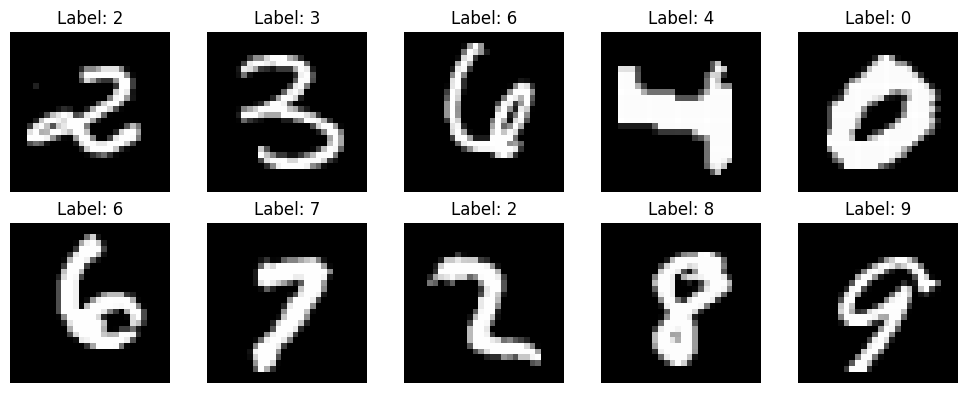

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout(); plt.show()

In [6]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3)),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(10),
    layers.Activation("softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [8]:
history = model.fit(X_train, y_train,
                    epochs=10, batch_size=64,
                    validation_data=(X_val, y_val))

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.9199 - loss: 0.2588 - val_accuracy: 0.9717 - val_loss: 0.0900
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.9751 - loss: 0.0807 - val_accuracy: 0.9826 - val_loss: 0.0550
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9822 - loss: 0.0586 - val_accuracy: 0.9865 - val_loss: 0.0437
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.9858 - loss: 0.0443 - val_accuracy: 0.9889 - val_loss: 0.0402
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.9885 - loss: 0.0365 - val_accuracy: 0.9846 - val_loss: 0.0485
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 17s 33ms/step - accuracy: 0.9902 - loss: 0.0305 - val_accuracy: 0.9869 - val_loss: 0.0405
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.9924 - loss: 0.0266 - val_accuracy: 0.9888 - val_loss: 0.0398
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9932 - loss: 0.0220 - 

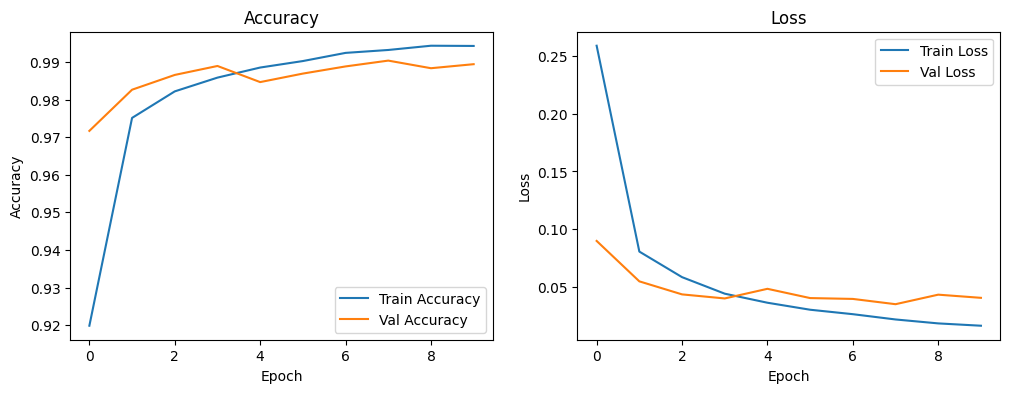

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.show()

Validation accuracy: 0.9894


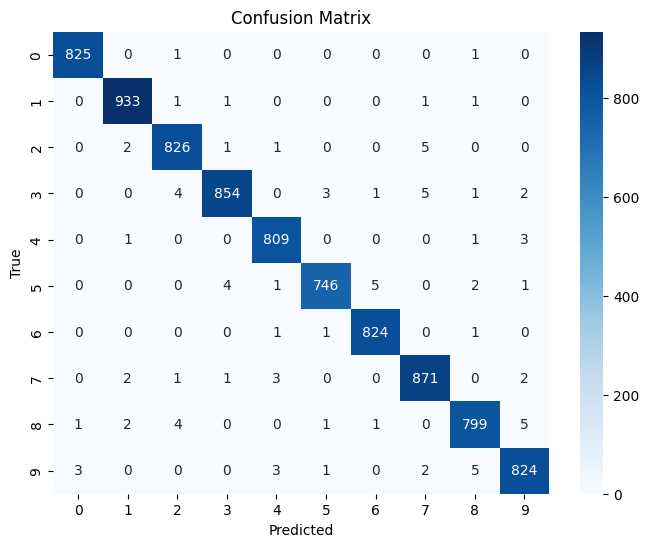

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       827
           1       0.99      1.00      0.99       937
           2       0.99      0.99      0.99       835
           3       0.99      0.98      0.99       870
           4       0.99      0.99      0.99       814
           5       0.99      0.98      0.99       759
           6       0.99      1.00      0.99       827
           7       0.99      0.99      0.99       880
           8       0.99      0.98      0.98       813
           9       0.98      0.98      0.98       838

    accuracy                           0.99      8400
   macro avg       0.99      0.99      0.99      8400
weighted avg       0.99      0.99      0.99      8400



In [10]:
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation accuracy: {val_acc:.4f}")

y_pred = np.argmax(model.predict(X_val, verbose=0), axis=1)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_val, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_val, y_pred))

Misclassified: 89 of 8400


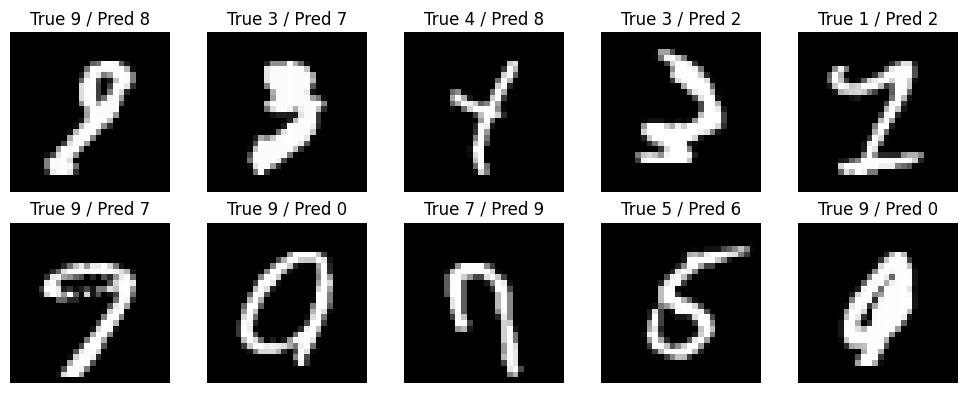

In [11]:
wrong = np.where(y_pred != y_val)[0]
print("Misclassified:", len(wrong), "of", len(y_val))

plt.figure(figsize=(10, 4))
for k, i in enumerate(wrong[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(X_val[i].reshape(28, 28), cmap="gray")
    plt.title(f"True {y_val[i]} / Pred {y_pred[i]}")
    plt.axis("off")
plt.tight_layout(); plt.show()

In [12]:
model.save("mnist_cnn_model.keras")

from google.colab import files
files.download("mnist_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
loaded = tf.keras.models.load_model("mnist_cnn_model.keras")
print("Loaded OK. Val accuracy:", loaded.evaluate(X_val, y_val, verbose=0)[1])

Loaded OK. Val accuracy: 0.9894047379493713


In [14]:
from PIL import Image

def prepare(path):
    img = Image.open(path).convert("L")
    arr = np.array(img, dtype="float32")
    if arr.mean() > 127:                          # dark digit on light paper -> invert
        arr = 255 - arr
    ys, xs = np.where(arr > 60)                   # crop to the digit
    arr = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = arr.shape; s = max(h, w)               # pad to square
    sq = np.zeros((s, s), dtype="float32")
    sq[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = arr
    small = np.array(Image.fromarray(sq).resize((20, 20), Image.LANCZOS))
    out = np.zeros((28, 28), dtype="float32")
    out[4:24, 4:24] = np.clip(small, 0, 255)      # centre in 28x28 like MNIST
    return (out / 255.0).reshape(1, 28, 28, 1)

Saving Screenshot 2026-11-05 210000.png to Screenshot 2026-11-05 210000.png


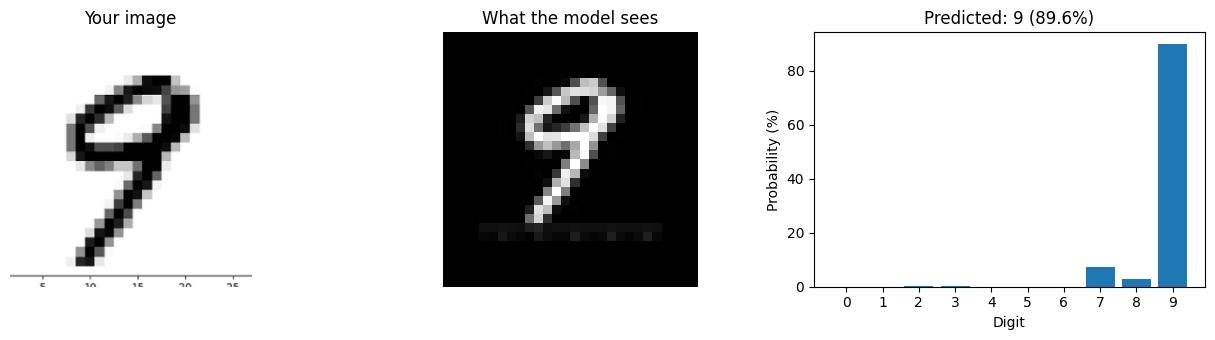

In [16]:
from google.colab import files
up = files.upload()
IMG_PATH = list(up.keys())[0]

x = prepare(IMG_PATH)
probs = loaded.predict(x, verbose=0)[0]
label = int(np.argmax(probs))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].imshow(Image.open(IMG_PATH)); ax[0].set_title("Your image"); ax[0].axis("off")
ax[1].imshow(x.reshape(28, 28), cmap="gray"); ax[1].set_title("What the model sees"); ax[1].axis("off")
ax[2].bar(range(10), probs * 100); ax[2].set_xticks(range(10))
ax[2].set_xlabel("Digit"); ax[2].set_ylabel("Probability (%)")
ax[2].set_title(f"Predicted: {label} ({probs[label]*100:.1f}%)")
plt.tight_layout(); plt.show()

Saving Screenshot 2026-11-05 210327.png to Screenshot 2026-11-05 210327.png


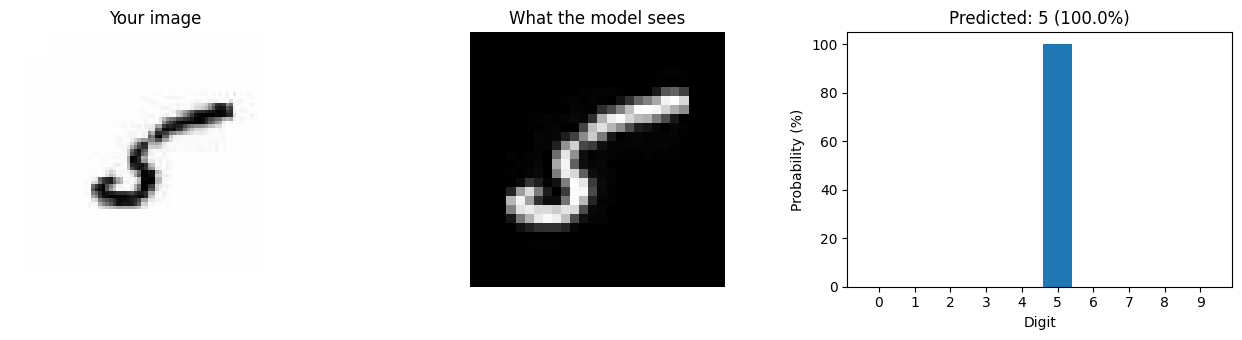

In [18]:
from google.colab import files
up = files.upload()
IMG_PATH = list(up.keys())[0]

x = prepare(IMG_PATH)
probs = loaded.predict(x, verbose=0)[0]
label = int(np.argmax(probs))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].imshow(Image.open(IMG_PATH)); ax[0].set_title("Your image"); ax[0].axis("off")
ax[1].imshow(x.reshape(28, 28), cmap="gray"); ax[1].set_title("What the model sees"); ax[1].axis("off")
ax[2].bar(range(10), probs * 100); ax[2].set_xticks(range(10))
ax[2].set_xlabel("Digit"); ax[2].set_ylabel("Probability (%)")
ax[2].set_title(f"Predicted: {label} ({probs[label]*100:.1f}%)")
plt.tight_layout(); plt.show()